# S&P 500 (GSPC) 日足

In [1]:
import sys

path_up = ".."
if not path_up in sys.path:
    sys.path.append(path_up)

In [2]:
import datetime

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import mplfinance as mpf
import numpy as np
import pandas as pd
import yfinance as yf

In [3]:
symbol1 = "^GSPC"
yticker1 = yf.Ticker(symbol1)
df1 = yticker1.history(period="6mo", interval="1d")
df1

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-05-18 00:00:00-04:00,7415.069824,7434.060059,7353.169922,7403.049805,5489500000,0.0,0.0
2026-05-19 00:00:00-04:00,7375.750000,7395.319824,7333.680176,7353.609863,5441140000,0.0,0.0
2026-05-20 00:00:00-04:00,7369.189941,7435.689941,7357.459961,7432.970215,5384150000,0.0,0.0
2026-05-21 00:00:00-04:00,7410.779785,7465.959961,7389.479980,7445.720215,5440620000,0.0,0.0
2026-05-22 00:00:00-04:00,7468.819824,7506.319824,7463.290039,7473.470215,4952440000,0.0,0.0
...,...,...,...,...,...,...,...
2026-11-10 00:00:00-05:00,7513.089844,7543.919922,7470.430176,7520.930176,5056350000,0.0,0.0
2026-11-11 00:00:00-05:00,7586.649902,7647.200195,7571.879883,7619.379883,4493200000,0.0,0.0
2026-11-12 00:00:00-05:00,7550.839844,7652.759766,7550.839844,7592.399902,4693040000,0.0,0.0


In [4]:
def plot_month(symbol, yticker, df):
    FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
    fm.fontManager.addfont(FONT_PATH)
    
    # FontPropertiesオブジェクト生成（名前の取得のため）
    font_prop = fm.FontProperties(fname=FONT_PATH)
    font_prop.get_name()
    
    plt.rcParams["font.family"] = font_prop.get_name()
    plt.rcParams["font.size"] = 11
    
    fig, ax = plt.subplots(figsize=(9, 3))
    
    mpf.plot(
        df,
        type="candle",
        style="default",
        datetime_format="%m/%d",
        xrotation=0,
        update_width_config=dict(candle_linewidth=0.75),
        ax=ax,
    )
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid()
    
    if "longName" in yticker.info:
        ax.set_title(f"{yticker.info['longName']} ({symbol})")
    elif "shortName" in yticker.info:
        ax.set_title(f"{yticker.info['shortName']} ({symbol})")
    else:
        ax.set_title(f"{symbol}")
    
    plt.tight_layout()
    #plt.savefig(get_name_15min_chart(code, dt_first))
    plt.show()

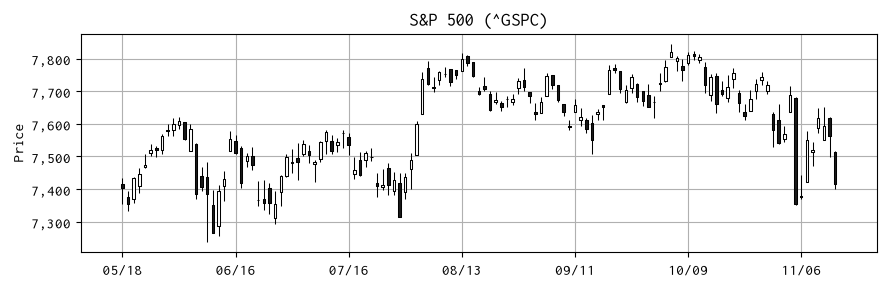

In [5]:
plot_month(symbol1, yticker1, df1)